## Lab 4: Sampling, Quantization, and Frequency Transforms

In [12]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.fft import fft, fft2, fftshift, ifft2, ifftshift, dct, idct
img = cv2.imread('./mountains.jpg')

---
## Problem 1 — Image Sampling and Quantization

1. Simulate spatial *sampling* (down-sample then up-sample) and amplitude *quantization* (reduce bit depth).  
2. Plot intensity histograms for the original and quantized images to visualise how quantization bins the distribution.

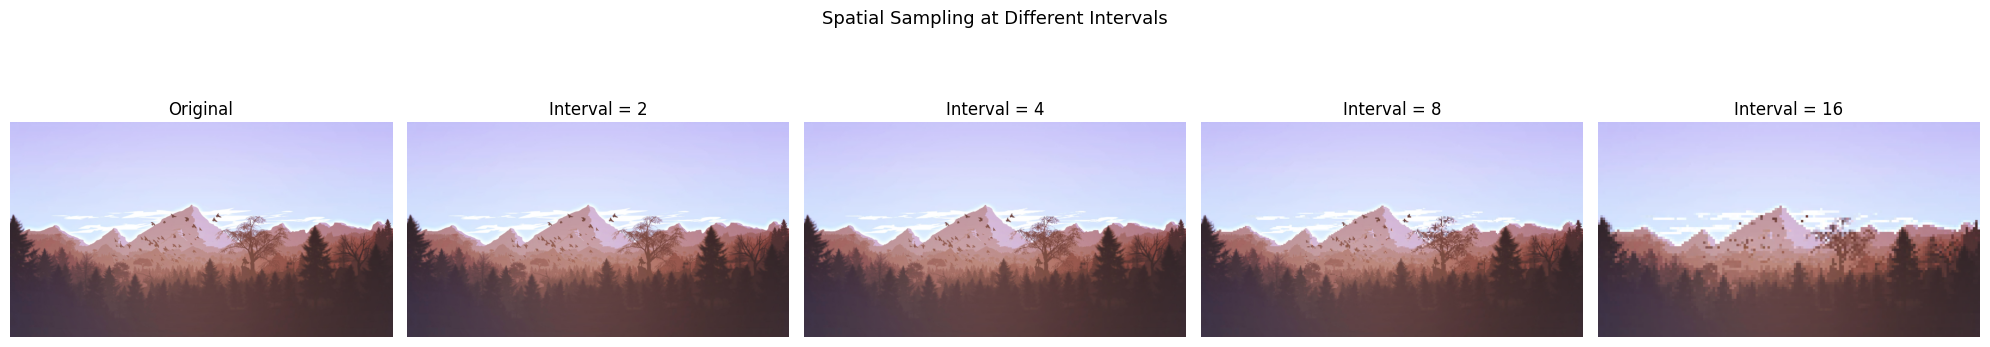

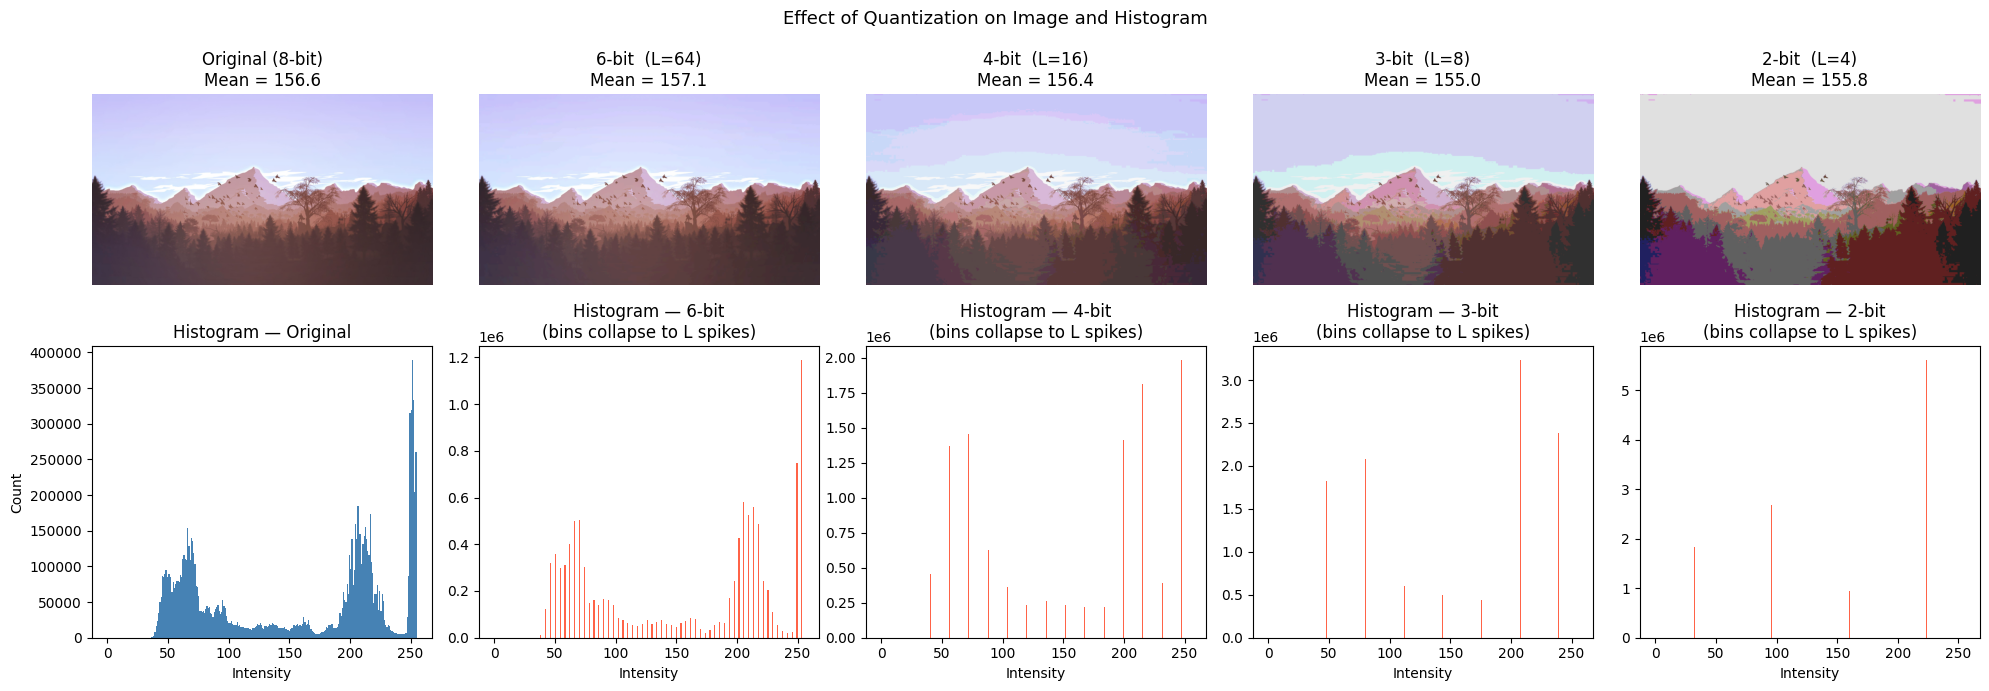

In [14]:
def sample_image(image, sampling_interval):
    h, w = image.shape[:2]
    small = image[::sampling_interval, ::sampling_interval]
    sampled = cv2.resize(small, (w, h), interpolation=cv2.INTER_NEAREST)
    return sampled


def quantize_image(image, num_levels):
    step = 256 / num_levels
    bins = np.floor(image.astype(np.float64) / step).astype(np.int32)
    reconstructed = (bins * step + step / 2).astype(np.float64)
    quantized = np.clip(reconstructed, 0, 255).astype(np.uint8)
    return quantized


def plot_sampling_results(original, intervals):
    fig, axes = plt.subplots(1, len(intervals) + 1, figsize=(4 * (len(intervals) + 1), 4))
    axes[0].imshow(original, cmap='gray', vmin=0, vmax=255)
    axes[0].set_title('Original')
    axes[0].axis('off')
    for ax, s in zip(axes[1:], intervals):
        ax.imshow(sample_image(original, s), cmap='gray', vmin=0, vmax=255)
        ax.set_title(f'Interval = {s}')
        ax.axis('off')
    plt.suptitle('Spatial Sampling at Different Intervals', fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()


def plot_quantization_histograms(original, bit_depths):
    n_cols = len(bit_depths) + 1
    fig, axes = plt.subplots(2, n_cols, figsize=(4 * n_cols, 7))

    axes[0, 0].imshow(original, cmap='gray', vmin=0, vmax=255)
    axes[0, 0].set_title('Original (8-bit)\n'
                          f'Mean = {original.mean():.1f}')
    axes[0, 0].axis('off')
    axes[1, 0].hist(original.ravel(), bins=256, range=(0, 255),
                    color='steelblue', edgecolor='none')
    axes[1, 0].set_xlabel('Intensity')
    axes[1, 0].set_ylabel('Count')
    axes[1, 0].set_title('Histogram — Original')

    for col, bits in enumerate(bit_depths, start=1):
        levels = 2 ** bits
        q = quantize_image(original, levels)
        axes[0, col].imshow(q, cmap='gray', vmin=0, vmax=255)
        axes[0, col].set_title(f'{bits}-bit  (L={levels})\n'
                                f'Mean = {q.mean():.1f}')
        axes[0, col].axis('off')
        axes[1, col].hist(q.ravel(), bins=256, range=(0, 255),
                          color='tomato', edgecolor='none')
        axes[1, col].set_xlabel('Intensity')
        axes[1, col].set_title(f'Histogram — {bits}-bit\n'
                                '(bins collapse to L spikes)')

    plt.suptitle('Effect of Quantization on Image and Histogram', fontsize=13)
    plt.tight_layout()
    plt.show()


plot_sampling_results(img, intervals=[2, 4, 8, 16])
plot_quantization_histograms(img, bit_depths=[6, 4, 3, 2])

---
## Problem 2 — Discrete Transforms: DCT and FFT

1. Apply 1-D FFT along rows and columns independently, then compute 2-D FFT and display the magnitude spectrum.
2. Compute 2-D DCT. Compare *energy compaction* of DCT vs FFT and explain JPEG preference.

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.5002995658582283..20.225151374645595].


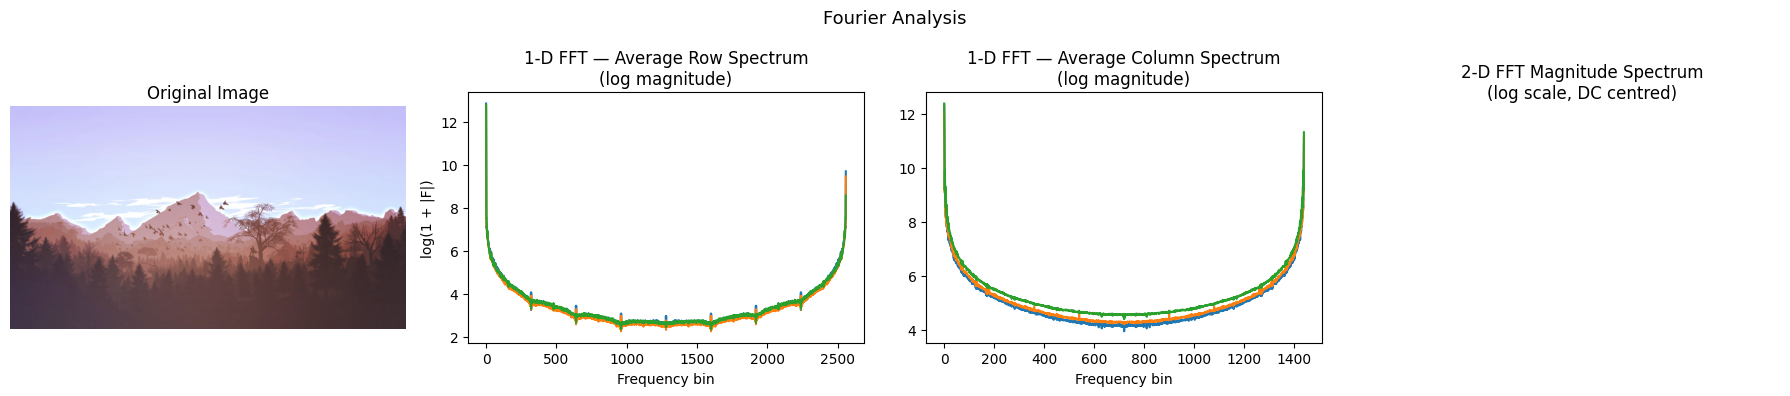

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [1.1014370364259219e-07..12.665074067554874].


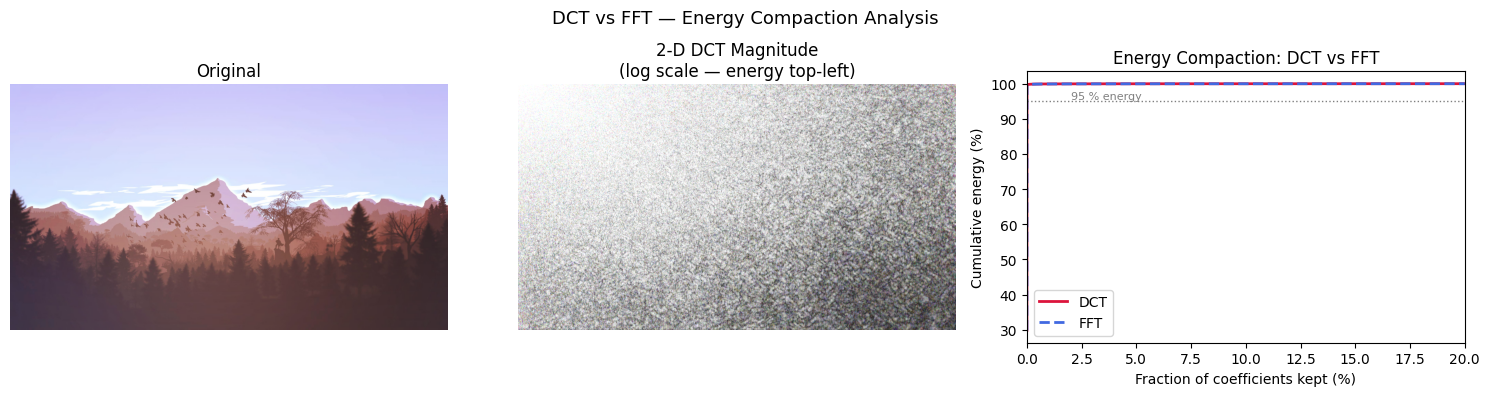

DCT: 0.00% of coefficients needed to capture 95% energy
FFT: 0.00% of coefficients needed to capture 95% energy


In [15]:
def fft_rows_then_cols(image):
    float_img = image.astype(np.float64)
    F_rows = np.fft.fft(float_img, axis=1)
    F_2d   = np.fft.fft(F_rows,    axis=0)
    return F_rows, F_2d


def log_magnitude(F):
    return np.log1p(np.abs(F))


def plot_fft_analysis(image):
    F_rows, F_2d = fft_rows_then_cols(image)
    F_shifted    = fftshift(F_2d)

    row_spec = log_magnitude(F_rows).mean(axis=0)
    col_spec = log_magnitude(
        np.fft.fft(image.astype(np.float64), axis=0)
    ).mean(axis=1)

    fig, axes = plt.subplots(1, 4, figsize=(18, 4))

    axes[0].imshow(image, cmap='gray')
    axes[0].set_title('Original Image')
    axes[0].axis('off')

    axes[1].plot(row_spec)
    axes[1].set_title('1-D FFT — Average Row Spectrum\n(log magnitude)')
    axes[1].set_xlabel('Frequency bin')
    axes[1].set_ylabel('log(1 + |F|)')

    axes[2].plot(col_spec)
    axes[2].set_title('1-D FFT — Average Column Spectrum\n(log magnitude)')
    axes[2].set_xlabel('Frequency bin')

    axes[3].imshow(log_magnitude(F_shifted), cmap='hot')
    axes[3].set_title('2-D FFT Magnitude Spectrum\n(log scale, DC centred)')
    axes[3].axis('off')

    plt.suptitle('Fourier Analysis', fontsize=13)
    plt.tight_layout()
    plt.show()

def compute_2d_dct(image):
    float_img = image.astype(np.float64)
    D = dct(dct(float_img, axis=1, norm='ortho'), axis=0, norm='ortho')
    return D


def energy_compaction_analysis(image):
    D = compute_2d_dct(image)
    _, F_2d = fft_rows_then_cols(image)

    dct_power = np.sort(D.ravel()**2)[::-1]
    fft_power = np.sort(np.abs(F_2d.ravel())**2)[::-1]

    dct_cumulative = np.cumsum(dct_power) / dct_power.sum() * 100
    fft_cumulative = np.cumsum(fft_power) / fft_power.sum() * 100

    n_coeff = np.arange(1, len(dct_cumulative) + 1)
    fraction = n_coeff / len(n_coeff) * 100

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].imshow(image, cmap='gray')
    axes[0].set_title('Original')
    axes[0].axis('off')

    axes[1].imshow(log_magnitude(D), cmap='hot')
    axes[1].set_title('2-D DCT Magnitude\n(log scale — energy top-left)')
    axes[1].axis('off')

    axes[2].plot(fraction, dct_cumulative, label='DCT', color='crimson', lw=2)
    axes[2].plot(fraction, fft_cumulative, label='FFT', color='royalblue',
                 lw=2, linestyle='--')
    axes[2].axhline(95, color='gray', linestyle=':', lw=1)
    axes[2].text(2, 95.5, '95 % energy', color='gray', fontsize=8)
    axes[2].set_xlabel('Fraction of coefficients kept (%)')
    axes[2].set_ylabel('Cumulative energy (%)')
    axes[2].set_title('Energy Compaction: DCT vs FFT')
    axes[2].legend()
    axes[2].set_xlim(0, 20)

    plt.suptitle('DCT vs FFT — Energy Compaction Analysis', fontsize=13)
    plt.tight_layout()
    plt.show()

    for name, cum in [('DCT', dct_cumulative), ('FFT', fft_cumulative)]:
        idx = np.searchsorted(cum, 95)
        pct = idx / len(cum) * 100
        print(f'{name}: {pct:.2f}% of coefficients needed to capture 95% energy')


plot_fft_analysis(img)
energy_compaction_analysis(img)

---
## Problem 3 — Frequency Domain Smoothing (Lowpass Filters)

Implement ILPF, BLPF, and GLPF in the frequency domain and compare their blurring behaviour.

ValueError: operands could not be broadcast together with shapes (1440,2560,3) (1440,2560) 

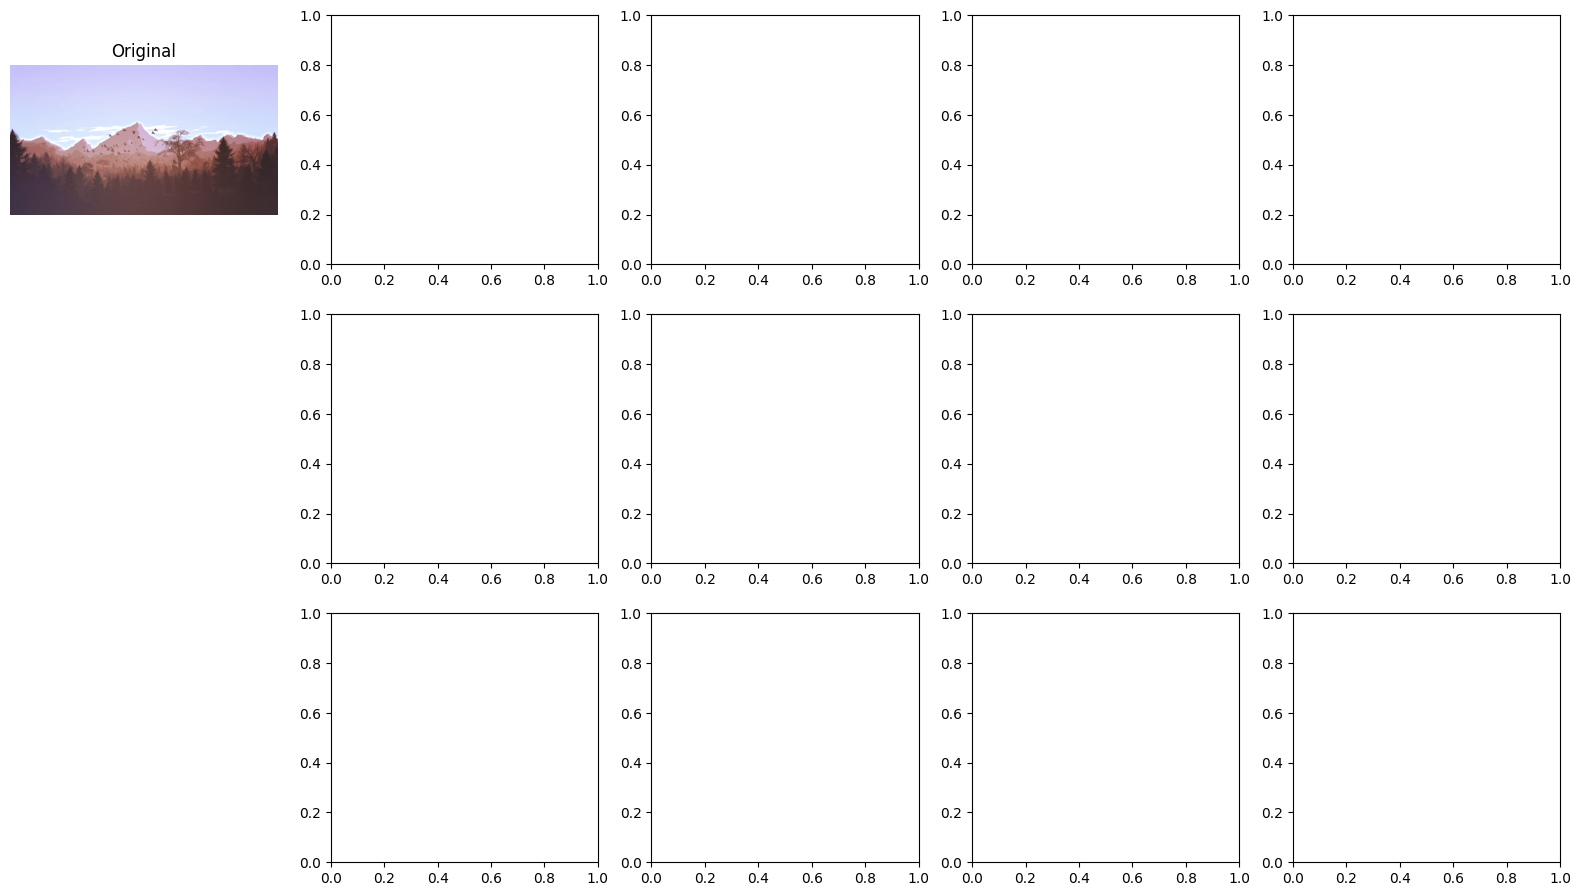

In [20]:
def distance_matrix(shape):
    H, W = shape[:2]
    u = np.fft.fftfreq(H) * H
    v = np.fft.fftfreq(W) * W
    U, V = np.meshgrid(u, v, indexing='ij')
    return np.sqrt(U**2 + V**2)


def ideal_lpf(shape, cutoff):
    return (distance_matrix(shape) <= cutoff).astype(np.float64)


def butterworth_lpf(shape, cutoff, order):
    D = distance_matrix(shape)
    return 1.0 / (1.0 + (D / cutoff) ** (2 * order))


def gaussian_lpf(shape, cutoff):
    D = distance_matrix(shape)
    return np.exp(-(D**2) / (2 * cutoff**2))


def apply_frequency_filter(image, H_filter):
    F = fftshift(fft2(image.astype(np.float64)))
    G = F * H_filter
    result = np.real(ifft2(ifftshift(G)))
    return np.clip(result, 0, 255).astype(np.uint8)


def compare_lpf_filters(image, cutoff=30):
    shape = image.shape[:2]

    H_ideal       = ideal_lpf(shape, cutoff)
    H_butter_1    = butterworth_lpf(shape, cutoff, order=1)
    H_butter_5    = butterworth_lpf(shape, cutoff, order=5)
    H_gauss       = gaussian_lpf(shape, cutoff)

    configs = [
        ('ILPF',            H_ideal,    'Hard binary disc → ringing in spatial domain'),
        ('BLPF  n=1',       H_butter_1, 'Very smooth roll-off → no ringing, slight blur'),
        ('BLPF  n=5',       H_butter_5, 'Steeper roll-off → sharper but mild ringing'),
        ('GLPF',            H_gauss,    'Gaussian → smoothest blur, zero ringing'),
    ]

    fig, axes = plt.subplots(3, len(configs) + 1, figsize=(4 * (len(configs) + 1), 11))

    axes[0, 0].imshow(image, cmap='gray')
    axes[0, 0].set_title('Original')
    axes[0, 0].axis('off')
    axes[1, 0].axis('off')
    axes[2, 0].axis('off')

    for col, (label, H, note) in enumerate(configs, start=1):
        filtered = apply_frequency_filter(image, H)

        mid = H.shape[0] // 2
        axes[0, col].plot(H[mid, :], color='darkblue')
        axes[0, col].set_title(f'{label}\nTransfer function H(u)')
        axes[0, col].set_ylim(-0.1, 1.1)
        axes[0, col].set_xlabel('Frequency bin')

        axes[1, col].imshow(filtered, cmap='gray')
        axes[1, col].set_title(f'{label}\nFiltered (D₀={cutoff})')
        axes[1, col].axis('off')

        diff = np.abs(image.astype(np.int16) - filtered.astype(np.int16))
        axes[2, col].imshow(diff, cmap='hot')
        axes[2, col].set_title(f'|Original − Filtered|\n{note}')
        axes[2, col].axis('off')

    plt.suptitle(f'Lowpass Filter Comparison  (D₀ = {cutoff})', fontsize=13)
    plt.tight_layout()
    plt.show()


compare_lpf_filters(img, cutoff=30)

---
## Problem 4 — Frequency Domain Sharpening (Highpass Filters)

1. Extract edge information using Ideal and Butterworth HPFs.
2. Implement **High-Boost Filtering** to sharpen while preserving the original tonal background.

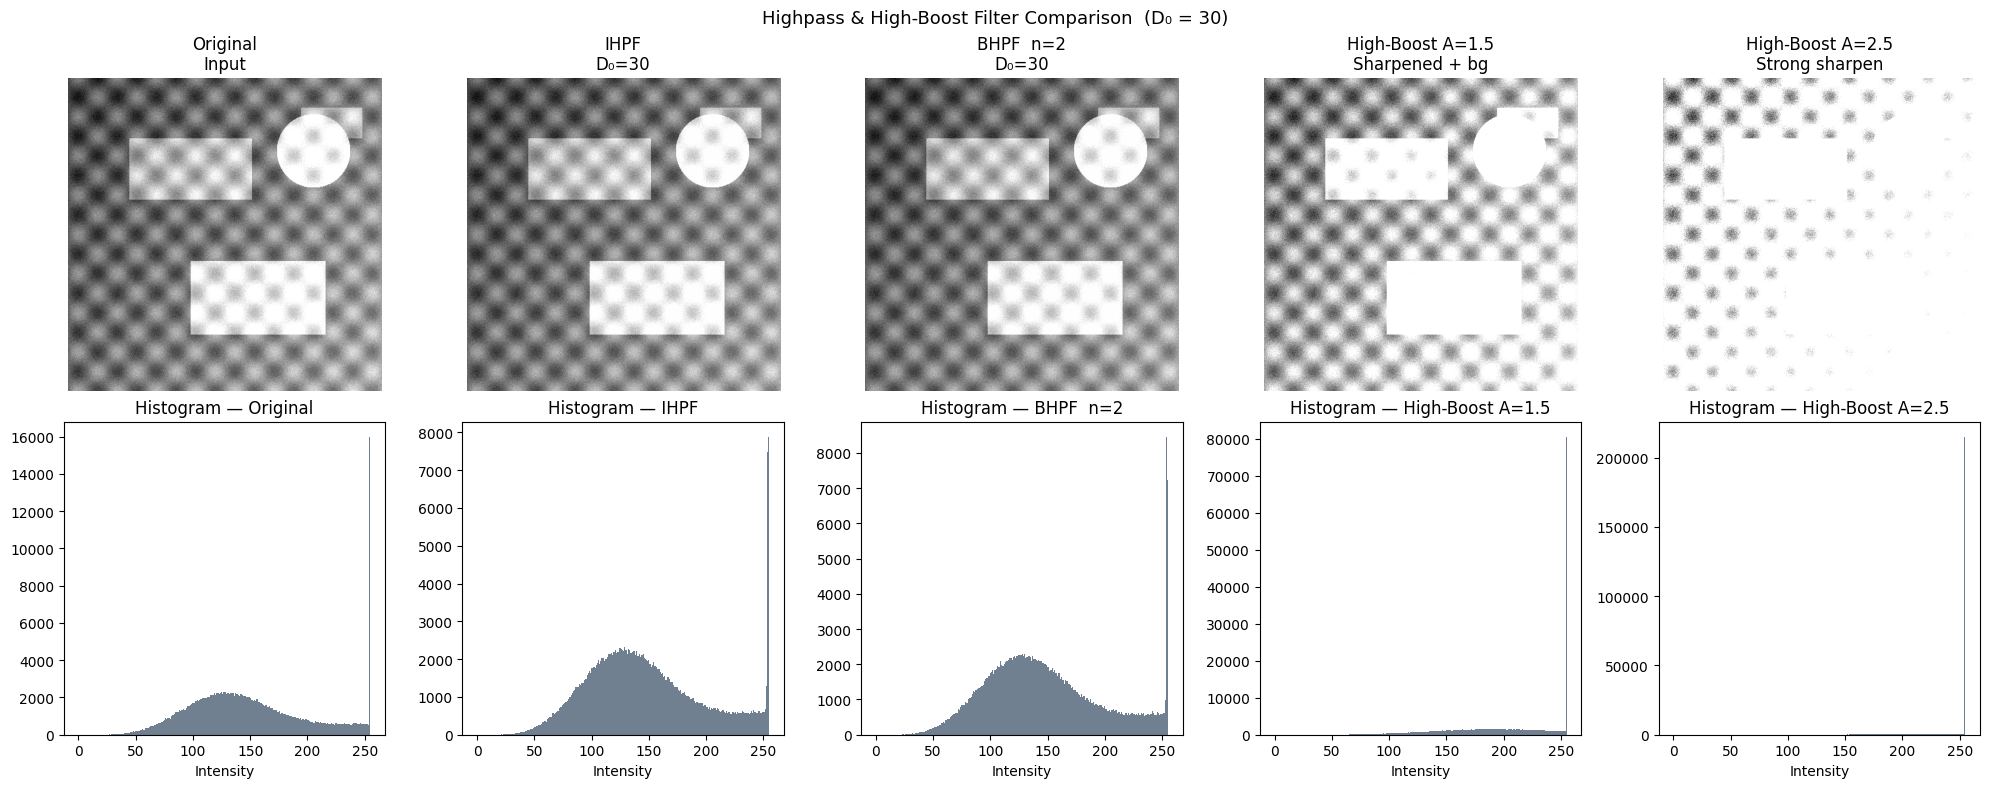

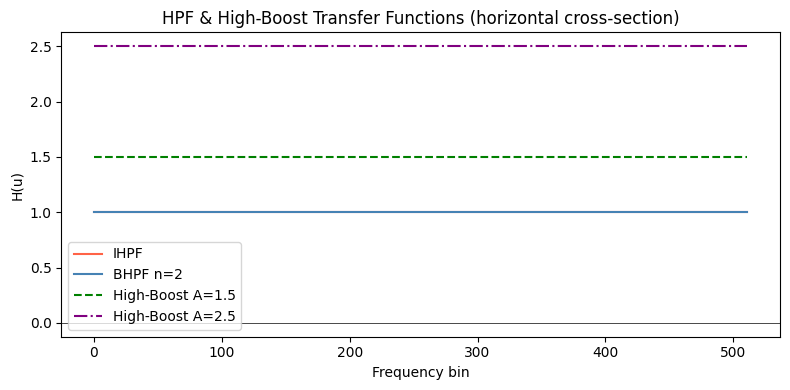

In [ ]:
def ideal_hpf(shape, cutoff):
    return 1.0 - ideal_lpf(shape, cutoff)


def butterworth_hpf(shape, cutoff, order):
    return 1.0 - butterworth_lpf(shape, cutoff, order)


def high_boost_filter(shape, cutoff, order, boost_factor):
    H_lpf = butterworth_lpf(shape, cutoff, order)
    H_hb  = boost_factor - H_lpf
    return H_hb


def compare_hpf_filters(image, cutoff=30):
    shape = image.shape

    H_ihpf   = ideal_hpf(shape, cutoff)
    H_bhpf   = butterworth_hpf(shape, cutoff, order=2)
    H_hb_15  = high_boost_filter(shape, cutoff, order=2, boost_factor=1.5)
    H_hb_25  = high_boost_filter(shape, cutoff, order=2, boost_factor=2.5)

    configs = [
        ('Original',        image,                                  'Input'),
        ('IHPF',            apply_frequency_filter(image, H_ihpf),  f'D₀={cutoff}'),
        ('BHPF  n=2',       apply_frequency_filter(image, H_bhpf),  f'D₀={cutoff}'),
        ('High-Boost A=1.5',apply_frequency_filter(image, H_hb_15), 'Sharpened + bg'),
        ('High-Boost A=2.5',apply_frequency_filter(image, H_hb_25), 'Strong sharpen'),
    ]

    fig, axes = plt.subplots(2, len(configs), figsize=(4 * len(configs), 8))

    for col, (label, result, note) in enumerate(configs):
        axes[0, col].imshow(result, cmap='gray')
        axes[0, col].set_title(f'{label}\n{note}')
        axes[0, col].axis('off')

        axes[1, col].hist(result.ravel(), bins=256, range=(0, 255),
                          color='slategray', edgecolor='none')
        axes[1, col].set_title(f'Histogram — {label}')
        axes[1, col].set_xlabel('Intensity')

    plt.suptitle(f'Highpass & High-Boost Filter Comparison  (D₀ = {cutoff})',
                 fontsize=13)
    plt.tight_layout()
    plt.show()

    fig2, ax = plt.subplots(figsize=(8, 4))
    mid = shape[0] // 2
    freq_axis = np.arange(shape[1])
    ax.plot(freq_axis, H_ihpf[mid, :],  label='IHPF',          color='tomato')
    ax.plot(freq_axis, H_bhpf[mid, :],  label='BHPF n=2',      color='steelblue')
    ax.plot(freq_axis, H_hb_15[mid, :], label='High-Boost A=1.5', color='green', ls='--')
    ax.plot(freq_axis, H_hb_25[mid, :], label='High-Boost A=2.5', color='purple', ls='-.')
    ax.axhline(0, color='black', lw=0.5)
    ax.set_xlabel('Frequency bin')
    ax.set_ylabel('H(u)')
    ax.set_title('HPF & High-Boost Transfer Functions (horizontal cross-section)')
    ax.legend()
    plt.tight_layout()
    plt.show()


compare_hpf_filters(img, cutoff=30)

---
## Problem 5 — Homomorphic Filtering

Correct non-uniform illumination by processing in the log domain, where the illumination component and reflectance component are additively separable, and then applying a frequency-domain filter that attenuates low frequencies (illumination) while boosting high frequencies (reflectance/detail).

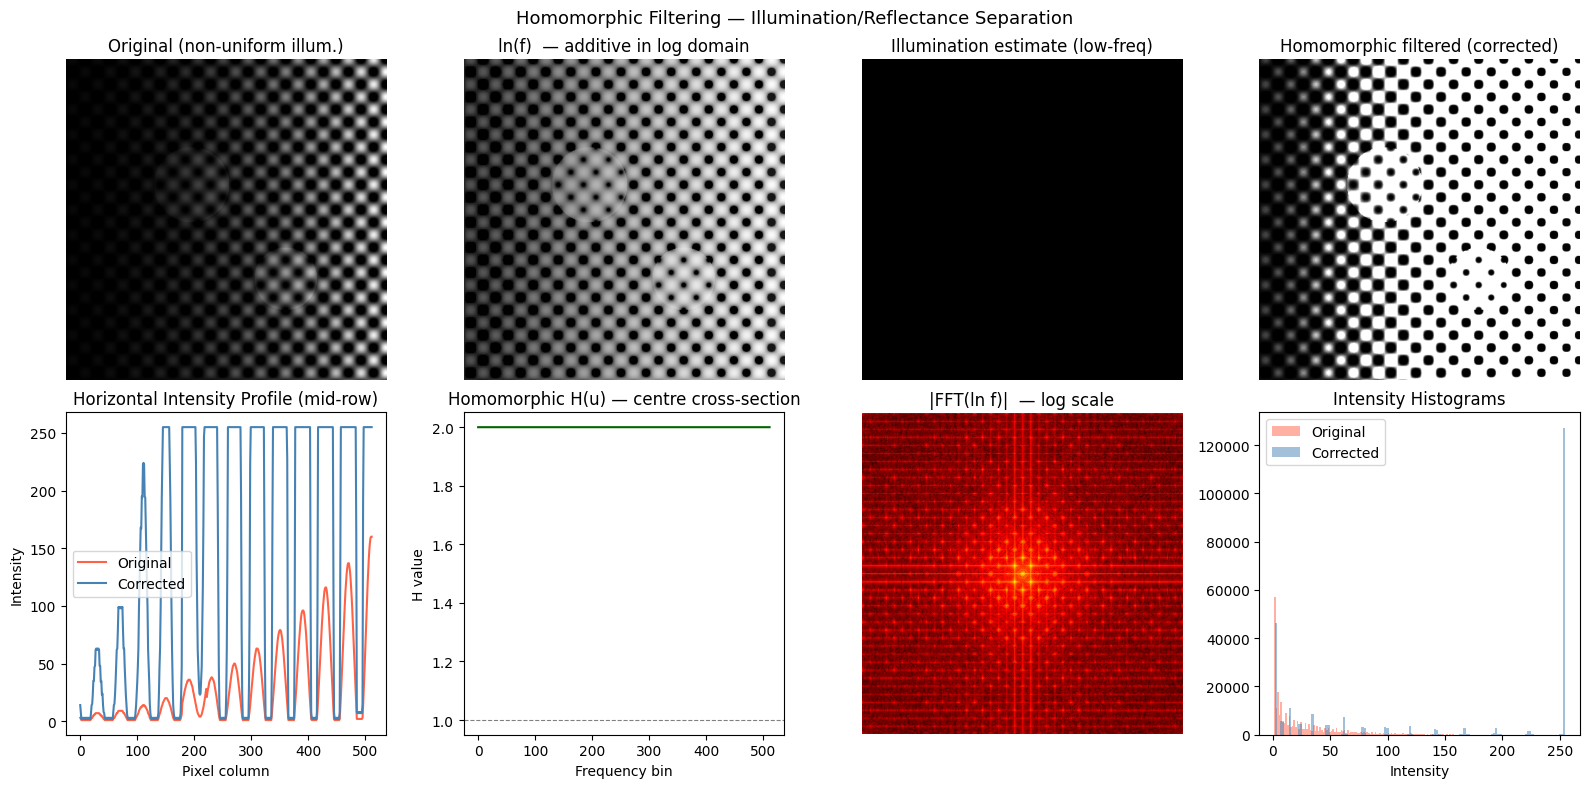

In [21]:
def make_nonuniform_image(size=512):
    rng = np.random.default_rng(7)
    y, x = np.mgrid[0:size, 0:size]
    illumination = 10 + 220 * (x / size)**2
    reflectance   = 0.3 + 0.5 * np.sin(2 * np.pi * x / 40) * np.cos(2 * np.pi * y / 40)
    reflectance  += 0.2 * (((x - 200)**2 + (y - 200)**2) < 60**2)
    reflectance  += 0.15 * (((x - 350)**2 + (y - 350)**2) < 50**2)
    reflectance   = np.clip(reflectance, 0.01, 1.0)   # avoid log(0)
    raw = illumination * reflectance
    raw = np.clip(raw, 1, 255)
    return raw.astype(np.uint8)


def homomorphic_filter(image, cutoff=30, gamma_low=0.25, gamma_high=2.0, order=2):
    ln_f = np.log1p(image.astype(np.float64))
    F = fftshift(fft2(ln_f))
    H_lpf = butterworth_lpf(image.shape, cutoff, order)
    H = (gamma_high - gamma_low) * (1.0 - H_lpf) + gamma_low

    G = F * H

    g = np.real(ifft2(ifftshift(G)))

    corrected = np.expm1(g)
    corrected = np.clip(corrected, 0, 255).astype(np.uint8)
    return corrected, H


def plot_homomorphic_results(image):
    corrected, H = homomorphic_filter(image)

    H_lpf = butterworth_lpf(image.shape, cutoff=30, order=2)
    ln_f  = np.log1p(image.astype(np.float64))
    F     = fftshift(fft2(ln_f))
    illum_log = np.real(ifft2(ifftshift(F * H_lpf)))
    illum_est = np.expm1(illum_log)
    illum_est = np.clip(illum_est, 0, 255).astype(np.uint8)

    fig, axes = plt.subplots(2, 4, figsize=(16, 8))

    for ax, data, title in zip(axes[0],
        [image,
         np.log1p(image.astype(np.float64)),
         illum_est,
         corrected],
        ['Original (non-uniform illum.)',
         'ln(f)  — additive in log domain',
         'Illumination estimate (low-freq)',
         'Homomorphic filtered (corrected)']):
        ax.imshow(data, cmap='gray')
        ax.set_title(title)
        ax.axis('off')

    row = image.shape[0] // 2
    axes[1, 0].plot(image[row, :],     label='Original',   color='tomato')
    axes[1, 0].plot(corrected[row, :], label='Corrected',  color='steelblue')
    axes[1, 0].set_title('Horizontal Intensity Profile (mid-row)')
    axes[1, 0].set_xlabel('Pixel column')
    axes[1, 0].set_ylabel('Intensity')
    axes[1, 0].legend()

    mid = H.shape[0] // 2
    axes[1, 1].plot(H[mid, :], color='darkgreen')
    axes[1, 1].set_title('Homomorphic H(u) — centre cross-section')
    axes[1, 1].set_xlabel('Frequency bin')
    axes[1, 1].set_ylabel('H value')
    axes[1, 1].axhline(1.0, color='gray', ls='--', lw=0.8)

    axes[1, 2].imshow(log_magnitude(F), cmap='hot')
    axes[1, 2].set_title('|FFT(ln f)|  — log scale')
    axes[1, 2].axis('off')

    axes[1, 3].hist(image.ravel(),     bins=128, alpha=0.5,
                    label='Original',  color='tomato')
    axes[1, 3].hist(corrected.ravel(), bins=128, alpha=0.5,
                    label='Corrected', color='steelblue')
    axes[1, 3].set_title('Intensity Histograms')
    axes[1, 3].set_xlabel('Intensity')
    axes[1, 3].legend()

    plt.suptitle('Homomorphic Filtering — Illumination/Reflectance Separation',
                 fontsize=13)
    plt.tight_layout()
    plt.show()


dark_img = make_nonuniform_image()
plot_homomorphic_results(dark_img)